# Jobs 51817042 and 51820549 — does the attention-only cell actually *do* direct deduction?

Finding 53 established that `no_mlp L=16 d192` at N=48 reaches `rho_50` **0.580**
on 3 of 3 seeds — a solve curve indistinguishable in quality from the `full`
family's shallowest free cell. A solve curve is a *behavioural* fact about
outputs. It does not say the model runs the algorithm, and the causal audit that
was always cited for that claim (**findings 27/28**: 350/350 round-0 flips,
0/350 emissions when the forcing was broken, 0.980 chaining) was run on
**N=24, full-architecture** checkpoints and **never once on a `no_mlp` cell**.

Stages Q and R are that audit, rerun where the claim is actually made. They are
two halves of one question and are reported in one deck:

| stage | what one token edit changes | what it tests |
|---|---|---|
| **Q** (`51817042`) | a **HINT** — a fact the model was *given* | the elimination **rule** over given facts |
| **R** (`51820549`) | a colour the model **itself deduced** earlier | the **iteration** that makes it an algorithm |

Both stages ran the **same four checkpoints** (J2's three seeds plus a
`full L=12 d256` control), the **same `--seed-start 600000000`**, and **350
counterfactuals per arm** against the same absolute chance rate 1/q = **0.250**.

**The registered hypotheses**, from the docstrings of `scripts/stageq_score.py`
and `scripts/stager_score.py`, each committed by its own sbatch *before* the
first arm ran:

* **Q3 / R3 — the precondition, read first.** `clean_correct` ≥ **0.50**. Below
  it the stage is INCONCLUSIVE, not negative: a model that cannot do the case at
  all cannot be asked whether it follows an edit.
* **R1 — the ambiguity, read second and before any verdict on a low flip.**
  Editing an emitted deduction makes the prefix inconsistent with the graph, so a
  model that *notices* and keeps its own value scores as "does not chain" while
  chaining perfectly in free generation. `reverts_to_original` separates them: a
  flip below the gate with a higher revert rate is **DETECTION-AMBIGUOUS**, never
  a negative.
* **Q0 / R0 — the gate.** flip ≥ **0.60** on ≥ 2 of 3 seeds, scored against
  **absolute chance**, never against the control.
* **Q2 / R2 — the confound and the ceiling.** No `full L=16 d192` exists at N=48,
  so the control differs in *both* `arch_mode` and shape; it is context, never
  the test. R2 additionally makes per-seed and arm-vs-control claims conditional
  on some arm falling below **0.95** — written in because **Q4 was caught by
  exactly that**.
* **R4 — what provenance costs.** chained flip − round-0 flip **within one arm**,
  bar **0.10**. The one cross-stage subtraction this programme licenses: the two
  stages share the instance *stream* (Q's 1200 instances are a prefix of R's
  2500) while their *case sets* are disjoint by construction, since a round-0
  node is not a round ≥ 1 node.
* **R5 — the round profile.** Composing layers predicts no decay with the round
  `v` was deduced in. Monotone decay would tie rounds to layers quantitatively,
  which is the most useful outcome a theory could have got here.

In [1]:
import os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
sys.path.insert(0, "/home/users/hshunt/.local/lib/claude-slides")
os.chdir("/home/users/hshunt/spin_gnn")

print("commit  ", subprocess.run(["git", "rev-parse", "HEAD"],
                                 capture_output=True, text=True).stdout.strip())
print("branch  ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                 capture_output=True, text=True).stdout.strip())
print("stage Q ", "51817042  (COMPLETED 00:04:22)")
print("stage R ", "51820549  (COMPLETED 00:04:39)")

commit   d15ae247c89f9546f8d86bd655dba6ad3f07b244
branch   sudoku-dd
stage Q  51817042  (COMPLETED 00:04:22)
stage R  51820549  (COMPLETED 00:04:39)


## 1. The four arms are the same four cells in both stages

That identity is not decoration: it is what makes **R4** a within-arm
subtraction rather than a comparison of two different models. Stage R's sbatch
checked all four cells field by field before any arm ran and would have exited
without running one; the same check is repeated here against the paths recorded
in the arms' own summaries.

In [2]:
import json
from scripts.stager_score import ARMS, OUT as RDIR

WANT = [("no_mlp", 16, 192, 0), ("no_mlp", 16, 192, 1),
        ("no_mlp", 16, 192, 2), ("full", 12, 256, 0)]
bad = 0
for (tag, label, qtag), w in zip(ARMS, WANT):
    sm = json.load(open(os.path.join(RDIR, tag, "chain_summary.json")))
    c = json.load(open(os.path.join(sm["checkpoint"], "config.json")))
    got = ((c.get("arch_mode") or "full"), c["num_layers"], c["d_model"], c["seed"])
    ok = (got == w and c["n_nodes"] == 48 and c["shuffle_adj"] and c["fall"])
    bad += not ok
    print("  %-11s %-7s L=%-2d d=%-3d s%d  n_nodes=%d shuffle_adj=%s fall=%s  %s"
          % (tag, got[0], got[1], got[2], got[3], c["n_nodes"], c["shuffle_adj"],
             c["fall"], "ok" if ok else "MISMATCH, registered %r" % (w,)))
assert bad == 0, "an arm is not the cell the registration names"
print()
print("all four arms are leak-free (--shuffle-adj) and FALL, as the audit requires")

  R_noff_s0   no_mlp  L=16 d=192 s0  n_nodes=48 shuffle_adj=True fall=True  ok
  R_noff_s1   no_mlp  L=16 d=192 s1  n_nodes=48 shuffle_adj=True fall=True  ok
  R_noff_s2   no_mlp  L=16 d=192 s2  n_nodes=48 shuffle_adj=True fall=True  ok
  R_full_ctrl full    L=12 d=256 s0  n_nodes=48 shuffle_adj=True fall=True  ok

all four arms are leak-free (--shuffle-adj) and FALL, as the audit requires


## 2. The registered scorers are the authority

Run as subprocesses so that what appears below is literally what
`scripts/stageq_score.py` and `scripts/stager_score.py` print — the same text
jobs `51817042` and `51820549` produced. No verdict in this notebook is
computed a second time in prose.

**Read R3 first, then R1, and only then R0.** A low flip rate is ambiguous
between "does not chain" and "detected the edit"; `reverts_to_original` is the
column that tells them apart.

In [3]:
for mod in ("scripts.stageq_score", "scripts.stager_score"):
    out = subprocess.run([sys.executable, "-u", "-m", mod],
                         capture_output=True, text=True)
    print("=" * 78)
    print(out.stdout)
    print("stderr:", out.stderr[-400:] if out.stderr else "(none)", " rc =", out.returncode)

STAGE Q -- does the ATTENTION-ONLY cell actually do direct deduction?

THIS DOCSTRING IS THE REGISTRATION. It is committed before the first arm runs.

WHY THIS STAGE EXISTS, AND WHY IT IS NOW THE PROGRAMME'S MAIN GAP. The brief
changed on 2026-11-10: the goal is the simplest / most analytically tractable
architecture THAT STILL LEARNS DIRECT DEDUCTION. That makes "still learns DD"
the GATE, not a nice-to-have -- and it has never been measured on an
attention-only cell. Findings 27/28 (350/350 round-0 counterfactual flips,
0/350 emissions with the forcing broken, 0.980 chaining) were all run on
FULL-architecture leak-free checkpoints at N=24. Every `no_mlp` claim in this
repo is a claim about matching a SOLVE CURVE. "Attention alone does the
deduction" has been written down but never tested.

THE COUNTERFACTUAL (unchanged, spin_gnn.sudoku_circuits.find_flippable_deductions).
Node u is forced when its known neighbours cover q-1 colours leaving c free.
Recolour the one neighbour uniquely 

## 3. The arms as levels

`clean_correct` is the precondition and is read before anything else;
`corrupt_flipped` is the gate; `reverts_to_original` is the detection signature
that keeps a low flip from being misread as a failure to chain.

In [4]:
from notebooks.make_stageqr_deck import load_qr, SHORT
from scripts.stageq_score import CHANCE, GATE
from scripts.stager_score import read_stageq_flip

S = load_qr()
q, r, ex = S["q"], S["r"], S["ex"]

print("STAGE Q -- one HINT edited, round-0 forcing")
print("%-9s %8s %9s %9s %10s" % ("arm", "clean", "flipped", "x chance", "logit gap"))
for i in range(4):
    print("%-9s %8.3f %9.3f %9.2f   %+.2f -> %+.2f"
          % (SHORT[i], q[i]["clean"], q[i]["flip"], q[i]["flip"] / CHANCE,
             q[i]["ld_clean"], q[i]["ld_corrupt"]))
print()
print("STAGE R -- one EMITTED DEDUCTION edited, round >= 1")
print("%-9s %8s %9s %9s %9s %10s" % ("arm", "clean", "flipped", "reverts",
                                     "x chance", "logit gap"))
for i in range(4):
    print("%-9s %8.3f %9.3f %9.3f %9.2f   %+.2f -> %+.2f"
          % (SHORT[i], r[i]["clean_correct"], r[i]["corrupt_flipped"],
             r[i]["reverts_to_original"], r[i]["corrupt_flipped"] / CHANCE,
             ex[i]["ld_clean"], ex[i]["ld_corrupt"]))
print()
print("R4, within one arm: chained flip - round-0 flip (registered bar 0.10)")
for i in range(4):
    print("  %-9s %+.4f" % (SHORT[i], r[i]["corrupt_flipped"] - read_stageq_flip(ARMS[i][2])))

STAGE Q -- one HINT edited, round-0 forcing
arm          clean   flipped  x chance  logit gap
s0           1.000     1.000      4.00   -17.23 -> +16.51
s1           1.000     0.997      3.99   -19.88 -> +21.40
s2           1.000     1.000      4.00   -16.89 -> +17.09
control      1.000     1.000      4.00   -17.01 -> +16.94

STAGE R -- one EMITTED DEDUCTION edited, round >= 1
arm          clean   flipped   reverts  x chance  logit gap
s0           1.000     0.994     0.006      3.98   -16.15 -> +15.61
s1           1.000     0.994     0.000      3.98   -18.43 -> +16.75
s2           1.000     0.994     0.003      3.98   -18.02 -> +16.82
control      1.000     0.931     0.043      3.73   -18.97 -> +7.77

R4, within one arm: chained flip - round-0 flip (registered bar 0.10)
  s0        -0.0057
  s1        -0.0029
  s2        -0.0057
  control   -0.0686


## 4. Two readings the raw numbers invite and do not support

**(i) The three seeds' identical `0.994` is a coincidence of counts, not
agreement.** Each seed misses exactly 2 of 350 — and **no two seeds miss the
same pair**. The misses are printed below as `node@round` keys, which is all the
behaviour CSV records: **the key is not an instance id**, so it *bounds* the
overlap rather than resolving it. Two consequences, both visible in the output:
seed 0's two misses carry the *same* key (`N42@r1`) and are therefore two
different instances — `find_chained_deductions` cannot return one node twice in
one round — and seed 1's two misses share no key with either other seed. If the
rate replicated *because the same cases are hard*, the union over the three
would be 2 keys; it is 4.

**(ii) The control's `0.931`, a provenance delta ~10× the arms', is not the
control chaining worse.** Most of its misses are `reverts_to_original` —
precisely **R1**'s detection signature — so the `full L=12 d256` solver is the
one more likely to *notice* the prefix was edited and keep its own value. It is
shape-confounded either way (Q2/R2) and is context, never the test.

In [5]:
print("misses, by arm")
for i in range(4):
    print("  %-9s %d of %d missed, %d of those REVERT to the original answer"
          % (SHORT[i], ex[i]["n_miss"], ex[i]["n"], ex[i]["miss_reverts"]))
    print("            cases: %s" % " ".join(ex[i]["miss_keys"]))
union = {k for i in range(3) for k in ex[i]["miss_keys"]}
print()
print("union of the three seeds' miss keys: %d distinct cases from %d misses"
      % (len(union), sum(ex[i]["n_miss"] for i in range(3))))
print("seeds share all misses:",
      all(set(ex[0]["miss_keys"]) == set(ex[i]["miss_keys"]) for i in (1, 2)))

misses, by arm
  s0        2 of 350 missed, 2 of those REVERT to the original answer
            cases: N42@r1 N42@r1
  s1        2 of 350 missed, 0 of those REVERT to the original answer
            cases: N29@r1 N10@r1
  s2        2 of 350 missed, 1 of those REVERT to the original answer
            cases: N41@r1 N42@r1
  control   24 of 350 missed, 15 of those REVERT to the original answer
            cases: N9@r1 N31@r1 N2@r1 N32@r1 N16@r1 N20@r1 N42@r1 N2@r1 N25@r1 N42@r1 N8@r1 N0@r1 N2@r1 N14@r1 N5@r1 N0@r1 N0@r1 N29@r1 N15@r1 N7@r1 N10@r1 N9@r1 N10@r1 N0@r1

union of the three seeds' miss keys: 4 distinct cases from 6 misses
seeds share all misses: False


## 5. The figures, as they appear on the slides

Drawn by importing `notebooks/make_stageqr_deck` and calling the same
module-level `draw_*` functions the deck hands to `slides.Deck.claim_page`, so
the notebook and the PDF cannot drift.

1. **Stage Q flip rate per arm**, against absolute chance and the registered gate.
2. **The logit gap**, before → after the edit, per arm.
3. **Stage R flip rate per arm** — the same picture one round deeper.
4. **R4, the provenance cost**, against its registered ±0.10 bar.
5. **R5, the round profile** — flip rate against the round the node was deduced in.

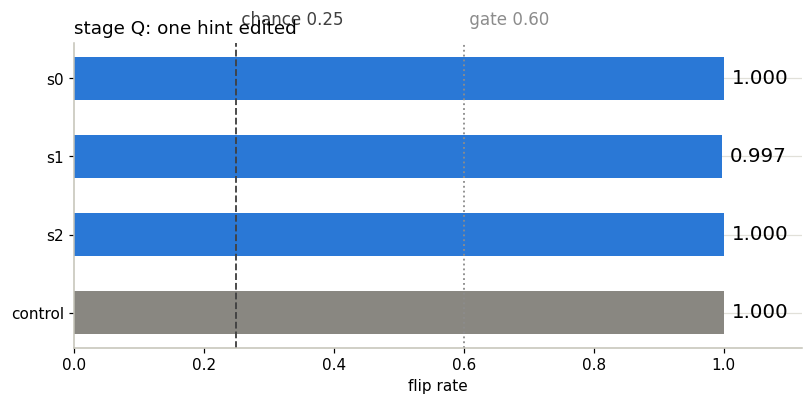

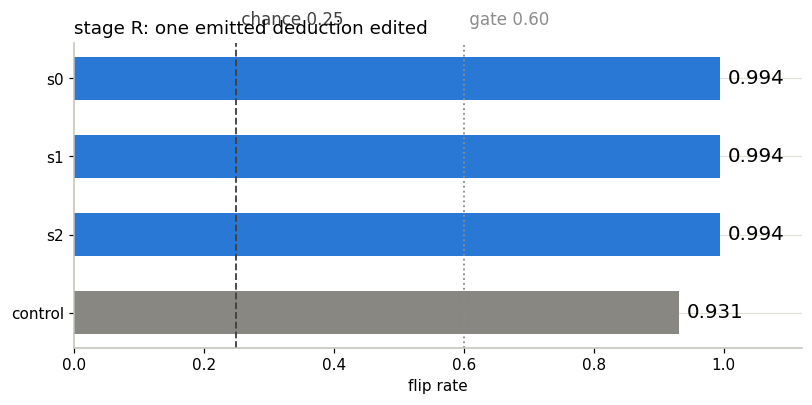

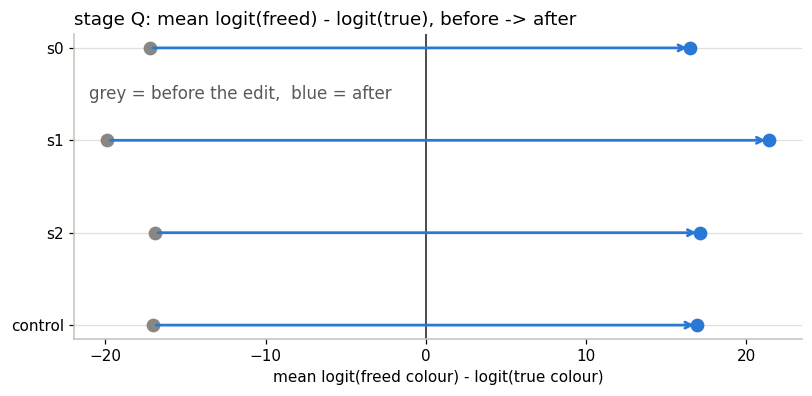

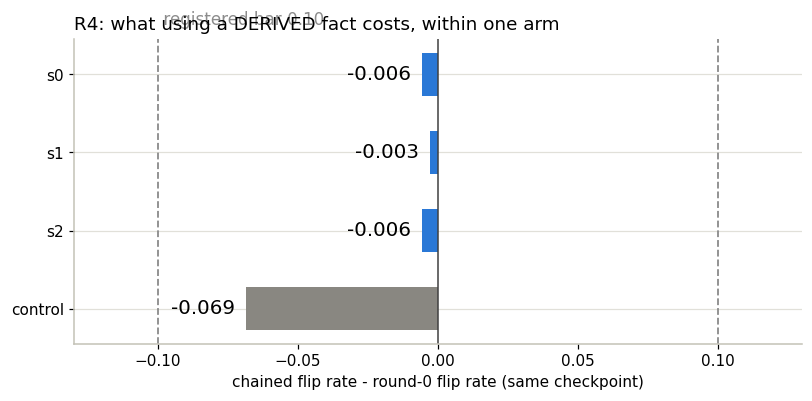

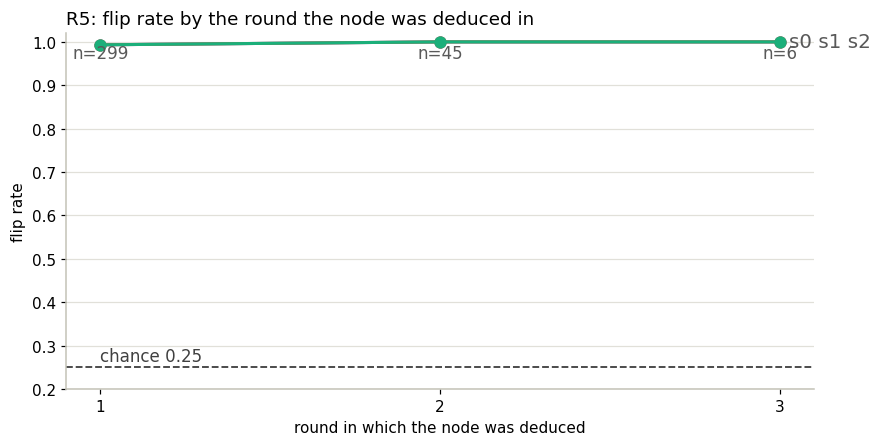

In [6]:
import matplotlib.pyplot as plt
from notebooks.make_stageqr_deck import (draw_flip, draw_logit, draw_provenance,
                                        draw_by_round)

qflip = [s["flip"] for s in q]
rflip = [s["corrupt_flipped"] for s in r]
deltas = [r[i]["corrupt_flipped"] - read_stageq_flip(ARMS[i][2]) for i in range(4)]

for vals, name in ((qflip, "stage Q: one hint edited"),
                   (rflip, "stage R: one emitted deduction edited")):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    draw_flip(ax, vals)
    ax.set_title(name, loc="left")
    plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
draw_logit(ax, [s["ld_clean"] for s in q], [s["ld_corrupt"] for s in q])
ax.set_title("stage Q: mean logit(freed) - logit(true), before -> after", loc="left")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
draw_provenance(ax, deltas)
ax.set_title("R4: what using a DERIVED fact costs, within one arm", loc="left")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.2))
draw_by_round(ax, r)
ax.set_title("R5: flip rate by the round the node was deduced in", loc="left")
plt.show()

## 6. Against the previous audit — which is *not* the same eval

Findings 27/28 are the numbers this programme has cited for "it is learning DD".
They were measured at **N=24** on a **full-architecture** checkpoint, on one
seed. These are therefore **not comparable numbers**, and that is the point: the
reason stages Q and R exist is that no audit of *this* cell on *this* graph size
existed at all.

In [7]:
print("%-16s %-22s %s" % ("quantity", "findings 27/28", "stages Q+R"))
for name, old, new in [
        ("graph size", "N=24", "N=48"),
        ("architecture", "full", "no_mlp L=16 d192"),
        ("seeds", "1", "3 (+1 full control)"),
        ("round-0 flip", "350 of 350", ", ".join("%.3f" % v for v in qflip[:3])),
        ("chained flip", "0.980", ", ".join("%.3f" % v for v in rflip[:3])),
        ("guard (broken)", "0 of 350 emissions", "NOT MEASURED on this cell")]:
    print("%-16s %-22s %s" % (name, old, new))

quantity         findings 27/28         stages Q+R
graph size       N=24                   N=48
architecture     full                   no_mlp L=16 d192
seeds            1                      3 (+1 full control)
round-0 flip     350 of 350             1.000, 0.997, 1.000
chained flip     0.980                  0.994, 0.994, 0.994
guard (broken)   0 of 350 emissions     NOT MEASURED on this cell


## 7. What this does and does not establish

**Established, on three seeds with the gates frozen before each run.** At N=48,
on the attention-only cell `no_mlp L=16 d192`, editing a single token that DD's
rule depends on moves the model's answer to the colour the edit frees: **1.000 /
0.997 / 1.000** when that token is a given hint (stage Q) and **0.994 / 0.994 /
0.994** when it is a colour the model itself emitted in an earlier round (stage
R), against an absolute chance rate of 0.250 and a registered gate of 0.60.
`clean_correct` is **1.000** on all eight arm-runs, so the precondition is not
doing the work. The mean logit gap reverses sign in both stages. **R4: using a
derived fact instead of a given one costs between −0.003 and −0.006 of flip
rate**, inside the registered 0.10 bar — so the cell is not merely applying an
inference rule once, it is eliminating against facts it derived, which is the
iteration.

**Not established — four limits, three of them registered in advance.**

* **Round-0 cases are the easy ones by construction.** `find_flippable_deductions`
  selects nodes whose every known neighbour is a hint, which is why
  `clean_correct` is 1.000 for a cell whose `rho_50` is 0.580. Stage Q alone
  would be satisfied by a one-step classifier; that is exactly why stage R exists.
* **The round profile is tested to 3 of 16 layers.** R5 is flat (r1 0.993,
  r2 1.000, r3 1.000) but the selected cases reach only **round 3**. "No decay up
  to the layer budget" is a claim about rounds 1–3, not about 16.
* **No seed-level claim is licensed by either stage.** Q4's rule fired on a 0.003
  spread against a 0.001 gap with every arm at the ceiling, and R's three
  identical 0.994s are a coincidence of counts on *different* cases. R2 was
  written in because of the first and reports the second honestly.
* **The guard third of findings 27/28 is still untested here.** 27/28 also found
  **0 of 350** emissions when the forcing was deliberately broken — the model
  declining to deduce what does not follow. No module in the current tree tests
  that on a `no_mlp` cell, so that third of the audit remains N=24-and-full-only.

**The control is context, not a test.** No `full L=16 d192` exists at N=48, so
the control differs in both `arch_mode` and shape. Its 0.931 is filed under
**detection**, since 15 of its 24 misses revert to the original answer.

**What this unblocks.** Stage P asks whether those 16 layers can be **one
weight-tied operator iterated 16 times**; that question is only worth asking
about a mechanism that is there, and these two stages are what show it is. The
remaining follow-up is **localization** (`--stages patching,heads`), which needs
a GPU and a fix to `sudoku_circuits._capture_clean`: it builds its hooks over
`range(len(model.encoder.layers))`, which is **1** for a tied cell, so on a stage
P checkpoint it would silently audit one site instead of sixteen and print a
plausible-looking table.